# Study 04 — Simulated Annealing (SA)

Exploratory study notebook: before wiring SA into the full experiment system, we check that it works,
learn how its hyper-parameters behave on our tuning problem, and see how it copes with every controller and plant.

**Questions**
1. Does the implementation actually optimise? (benchmark functions with known optimum)
2. Which hyper-parameters matter for controller tuning, and how much?
3. With a fixed evaluation budget, is it better to have a big population or many generations?
4. How well does it tune each controller on each plant — and where does it fail?

All runs use the project's own simulator, metrics and objective through
`smart_control.experiments.runner.run_single_experiment`. Only `numpy`, `matplotlib` and `control` are used.
⏱ Full run: about 5 minutes on a laptop.

## The algorithm

**Idea.** A *single* solution takes random Gaussian steps (σ = `step_size` × range, reflected back into
the bounds). Better moves are always accepted; worse ones with the Metropolis probability
$$P(\text{accept}) = \exp(-\Delta J / T),$$
and the temperature cools geometrically, $T_{k+1} = \alpha\,T_k$. Early on (hot) it explores; late (cold) it only descends.
The run stops early if $T$ falls below `final_temperature`.

Hyper-parameters to study: **step size**, **initial temperature** $T_0$, and the **cooling rate** α.

Note: SA has no population — for a fair comparison it gets the *same number of objective evaluations*
as the population methods (one initial point + N − 1 moves).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from study_utils import *          # project import, runners, benchmarks, plots
from smart_control.optimizers.simulated_annealing import SimulatedAnnealing

KEY, COLOR = "SA", OPT_COLORS["SA"]
print("Implementation defaults:")
for k, v in SimulatedAnnealing().default_settings().items():
    print(f"  {k:22s} {v}")

Implementation defaults:
  population_size        1
  max_iterations         300
  random_seed            42
  initial_temperature    1.0
  final_temperature      0.001
  cooling_rate           0.98
  step_size              0.1
  reheat_interval        0


## 1. Sanity check on benchmark functions

Before tuning controllers, make sure SA minimises functions whose optimum we know (all have minimum 0):
**Sphere** (one smooth bowl), **Rastrigin** (a grid of local minima) and **Rosenbrock** (a curved, narrow valley),
in 2, 5 and 10 dimensions, with ≈500 evaluations and 3 seeds.

In [2]:
bench = benchmark_runs(SimulatedAnnealing, budget(KEY, 20, 24))
benchmark_table(bench)

Function     dim  best f (mean of seeds)  worst seed
Sphere         2                0.002738    0.003794
Sphere         5                   0.316      0.4093
Sphere        10                   3.432       4.736
Rastrigin      2                   1.107       1.263
Rastrigin      5                   20.51       37.78
Rastrigin     10                   72.59       88.89
Rosenbrock     2                 0.03265     0.08338
Rosenbrock     5                   9.084       14.22
Rosenbrock    10                   60.46       71.58


Where does it sample? Each dot is one objective evaluation on 2-D Rastrigin.

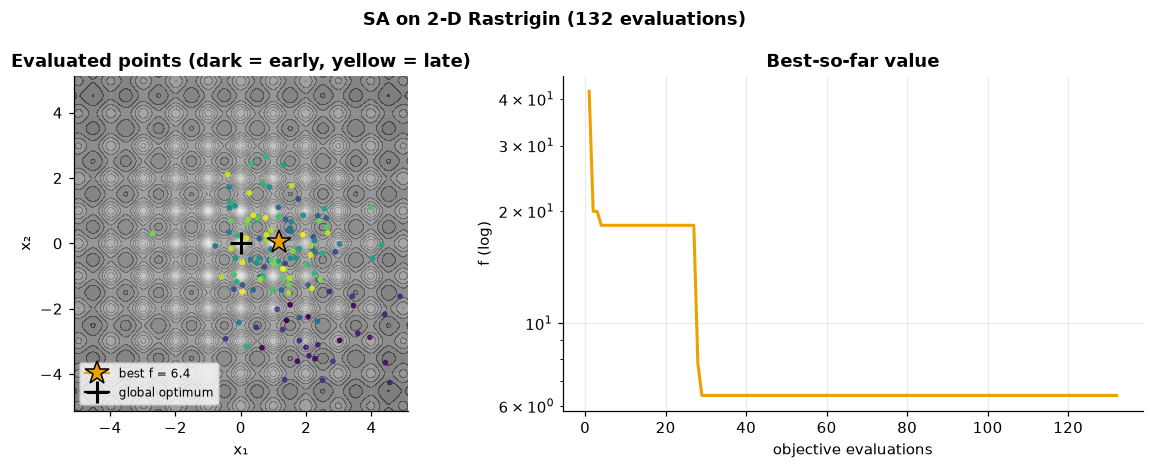

In [3]:
plot_search(SimulatedAnnealing, budget(KEY, 12, 10), COLOR, title="SA on 2-D Rastrigin (132 evaluations)")

## 2. Hyper-parameter study

**Test case:** PID on the 3rd-order plant — cheap to simulate, and sensitive enough to show differences.
Budget ≈60 evaluations, 3 seeds per setting; the heat-map shows **mean J** (± std), best setting outlined.

### 2a. step size (× range) × T₀

27 runs in 43 s


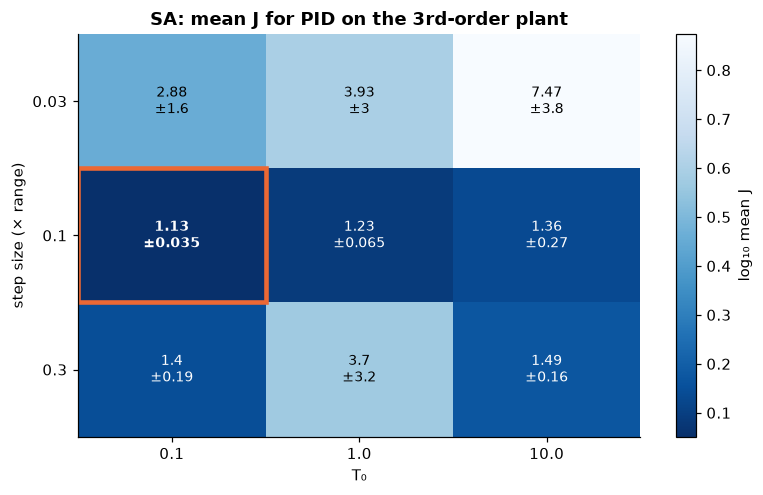

Best: step size (× range) = 0.1, T₀ = 0.1  ->  mean J = 1.125
Worst/best ratio: 6.6x


In [4]:
ROWS, COLS = [0.03, 0.1, 0.3], [0.1, 1.0, 10.0]
mean, std = sweep2d(SimulatedAnnealing, budget(KEY, 10, 5), 'step_size', ROWS, 'initial_temperature', COLS)
i, j = sweep_heatmap(mean, ROWS, COLS, "step size (× range)", "T₀",
                     "SA: mean J for PID on the 3rd-order plant", std=std)
print(f"Best: step size (× range) = {ROWS[i]}, T₀ = {COLS[j]}  ->  mean J = {mean[i, j]:.4g}")
print(f"Worst/best ratio: {mean.max() / mean.min():.1f}x")

### 2b. cooling rate α

Fast cooling freezes the search early (and can trigger the early stop at T < final_temperature); slow cooling keeps accepting worse moves.

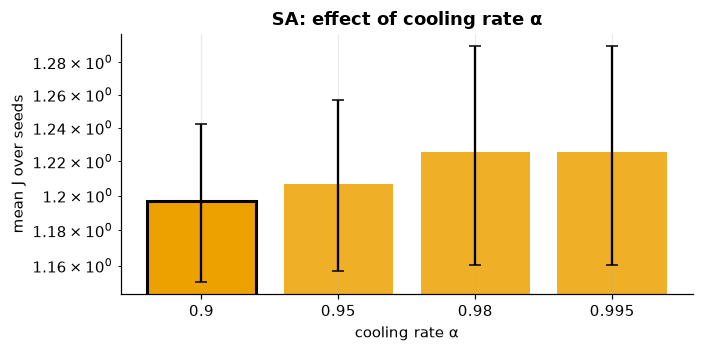

cooling rate α =    0.9   mean J = 1.197 ± 0.046
cooling rate α =   0.95   mean J = 1.207 ± 0.05
cooling rate α =   0.98   mean J = 1.225 ± 0.065
cooling rate α =  0.995   mean J = 1.225 ± 0.065


In [5]:
VALUES = [0.9, 0.95, 0.98, 0.995]
m1, s1 = sweep1d(SimulatedAnnealing, budget(KEY, 10, 5), 'cooling_rate', VALUES)
plot_sweep1d(VALUES, m1, s1, "cooling rate α", COLOR, "SA: effect of cooling rate α")
for v, m, sd in zip(VALUES, m1, s1):
    print(f"cooling rate α = {v!s:>6}   mean J = {m:.4g} ± {sd:.2g}")

## 3. How many moves are enough?

SA has no population/generation split, so instead we ask how much a *longer* run helps
(PID on the 3rd-order plant, 3 seeds).

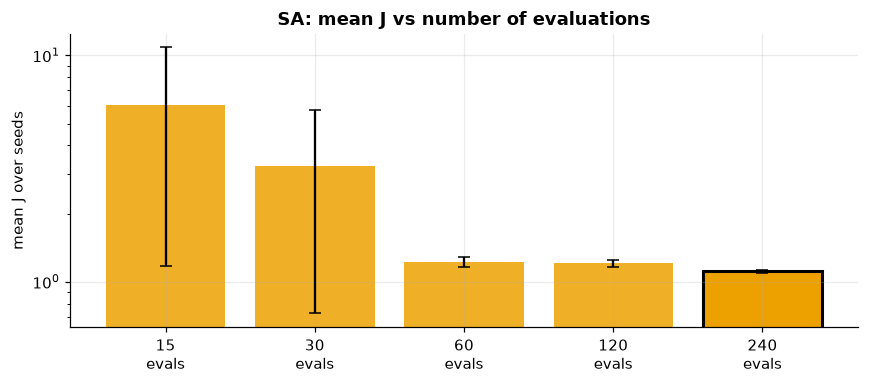

  15 evaluations   mean J = 6.007 ± 4.8
  30 evaluations   mean J = 3.235 ± 2.5
  60 evaluations   mean J = 1.225 ± 0.065
 120 evaluations   mean J = 1.204 ± 0.048
 240 evaluations   mean J = 1.11 ± 0.02


In [6]:
MOVES = [15, 30, 60, 120, 240]
means, stds = [], []
for n in MOVES:
    js = [run(SimulatedAnnealing, "PID", "third_order", {"max_iterations": n - 1}, seed)["best_fitness"]
          for seed in (42, 43, 44)]
    means.append(np.mean(js)); stds.append(np.std(js))
plot_budget_split([(n, 0) for n in MOVES], means, stds, COLOR, "SA: mean J vs number of evaluations")
for n, m, sd in zip(MOVES, means, stds):
    print(f"{n:4d} evaluations   mean J = {m:.4g} ± {sd:.2g}")

## 4. Every controller on every plant

The real question: **how does SA do on the actual tuning problems?**

* Budget: population 10 × 5 generations ⇒ **≈60 objective evaluations per run** (the *Extended* budget used in the final system).
* Hyper-parameters: the **implementation defaults** (so these numbers match the final system), not the sweep winners above.
* 3 independent seeds (42, 43, 44) per cell → 4 controllers × 3 plants × 3 seeds = 36 runs.
* Fuzzy runs dominate the runtime (25-rule inference at every simulation step).

In [7]:
records = run_matrix(SimulatedAnnealing, list(CONTROLLERS), PLANT_NAMES, budget(KEY, 10, 5), seeds=(42, 43, 44))

PID             2nd order seed 42  J =    0.5404  IAE =   0.306  settled = yes  (2.0 s)


PID             2nd order seed 43  J =    0.5967  IAE =    0.35  settled = yes  (1.9 s)


PID             2nd order seed 44  J =    0.5996  IAE =   0.424  settled = yes  (1.9 s)


PID             3rd order seed 42  J =     1.291  IAE =   0.618  settled = yes  (2.2 s)


PID             3rd order seed 43  J =     1.137  IAE =   0.536  settled = yes  (1.9 s)


PID             3rd order seed 44  J =     1.248  IAE =   0.606  settled = yes  (1.8 s)


... (26 outputs left out)

GP Controller   3rd order seed 44  J =     28.44  IAE =     4.3  settled = no   (2.2 s)


GP Controller   4th order seed 42  J =        33  IAE =    8.66  settled = no   (2.1 s)


GP Controller   4th order seed 43  J =        33  IAE =    8.66  settled = no   (1.7 s)


GP Controller   4th order seed 44  J =     31.03  IAE =    6.84  settled = no   (1.4 s)

36 runs in 340 s


### Results table
J is mean ± std over seeds; the metric columns are from the best seed.

In [8]:
summary_table(records)

Controller      Plant        J mean    ± std  settled     IAE  Ts (s)  Tr (s)    OS %      Ess
----------------------------------------------------------------------------------------------
PID             2nd order    0.5789   0.0273     3/3   0.306    0.78   0.469       0 0.000276
PID             3rd order     1.225   0.0648     3/3   0.536       2   0.984       0  0.00116
PID             4th order     62.73     37.9     1/3    7.98      20    14.6       0   0.0863
Neural Network  2nd order     23.24     6.91     2/3    1.25    8.79   0.753      22   0.0154
Neural Network  3rd order      31.9     3.51     0/3    3.96       —    1.21       0    0.173
Neural Network  4th order     41.41     12.1     0/3    7.73       —       —       0    0.174
Fuzzy           2nd order    0.6539   0.0288     3/3   0.409     0.7   0.506       0  0.00295
Fuzzy           3rd order     4.348     3.69     3/3   0.696    1.55    0.77       0   0.0089
Fuzzy           4th order     18.55     7.73     2/3    5.

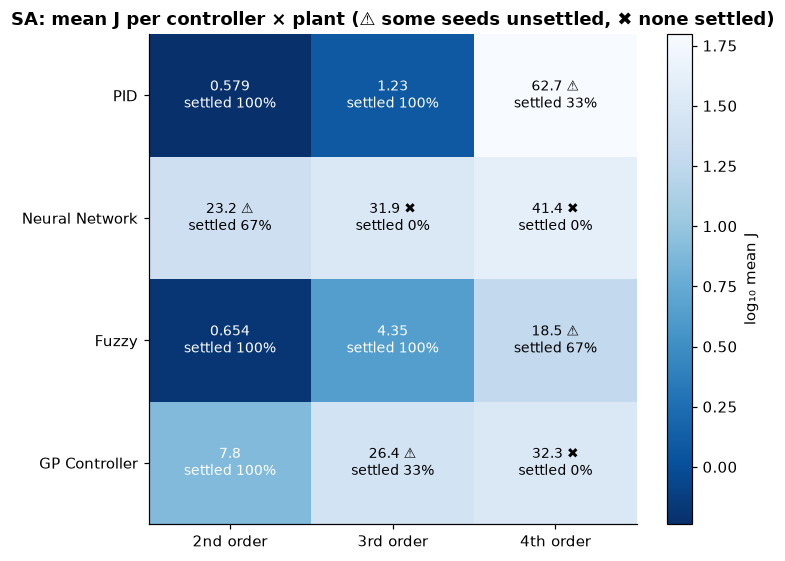

In [9]:
plot_matrix_heatmap(records, "SA: mean J per controller × plant (⚠ some seeds unsettled, ✖ none settled)")

### Step responses (best seed of each cell)

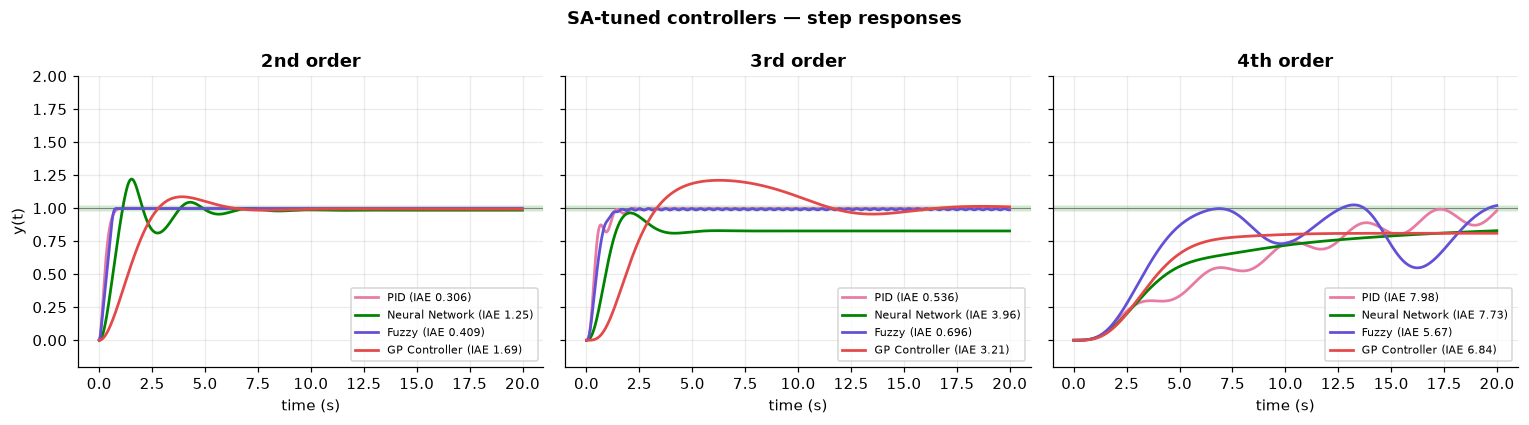

In [10]:
plot_step_grid(records, "SA-tuned controllers — step responses")

### Convergence
One line per seed; solid = 2nd, dashed = 3rd, dotted = 4th order.

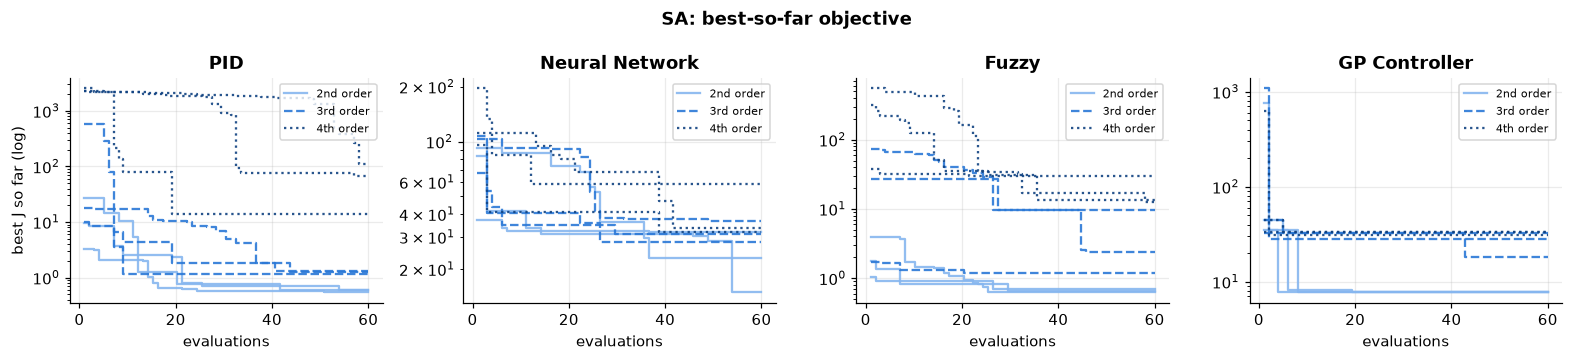

In [11]:
plot_convergence_grid(records, COLOR, "SA: best-so-far objective")

### Control effort on the 3rd-order plant
A good response is not enough if the actuator has to work unreasonably hard.

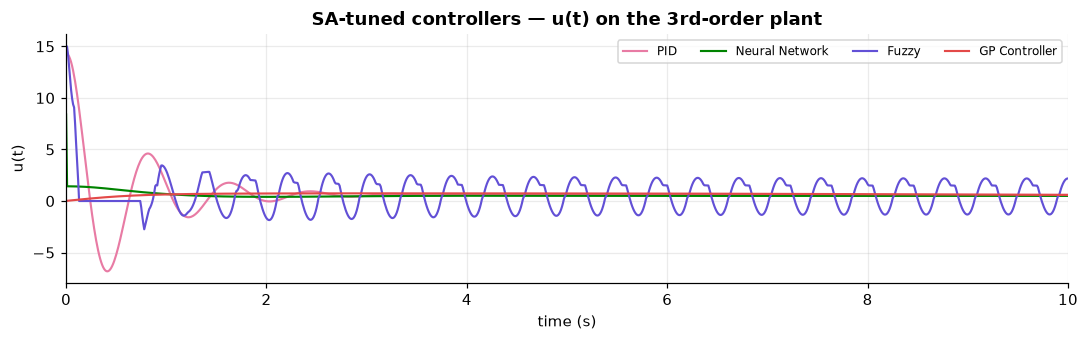

In [12]:
plot_control_effort(records, "third_order", "SA-tuned controllers — u(t) on the 3rd-order plant")

## Takeaways

**1. Middle of the pack on the benchmarks.** Good in 2-D (Rosenbrock ≈ 0.03), but a single random walker covers high-dimensional space slowly (10-D Sphere ≈ 3.4, Rastrigin ≈ 73). On 2-D Rastrigin the samples form one wandering trajectory rather than a cloud.

**2. The step size is what matters (6.6× spread).** Best **step size 0.1 with T₀ = 0.1** (J ≈ 1.13). Too-small steps (0.03 × range) cannot cross the PID bounds in 60 moves: J 2.9–7.5 whatever the temperature, worst with T₀ = 10. With step 0.1 the result is robust to T₀ (J 1.13–1.36 from T₀ = 0.1 to 10); step 0.3 is in between and noisier. The **cooling rate barely matters at this budget** (J 1.20–1.23 for α from 0.9 to 0.995): over 60 moves the temperature never gets low enough for the schedule to make a difference.

**3. Budget:** diminishing returns are clear — 15 → 60 evaluations improves J from ≈ 6.0 to ≈ 1.23, but quadrupling to 240 only reaches ≈ 1.11. Most of the gain comes in the first ~60 evaluations.

**4. On the real problems (≈60 evals, defaults): the most consistent tuner for low-dimensional controllers.**
- **Best PID results of all four studies** — 2nd order J ≈ 0.579 ± 0.027, 3rd order J ≈ 1.225 ± 0.065 (smallest seed spread anywhere).
- **Best Fuzzy results** on the 2nd-order (J ≈ 0.65) and 4th-order plants (J ≈ 18.6, 2/3 seeds settle).
- **Best neural network on the 2nd-order plant** (2/3 seeds settle).
- One weak spot: Fuzzy on the 3rd-order plant had one bad seed (J ≈ 9.5), and PID on the 4th-order plant still fails on 2/3 seeds.

**Implications for the full system:** with only 3 parameters, a local, step-by-step search beats population methods under a tiny budget. The default step size (0.1 × range) is already the right one; lowering T₀ to ≈ 0.1 gives a small further gain (J 1.23 → 1.13).